In [1]:
import os

import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np
import pandas as pd
import torch
from mediapipe.tasks.python import BaseOptions
from mediapipe.tasks.python.vision import (
    HandLandmarker,
    HandLandmarkerOptions,
    RunningMode,
)
from PIL import Image
from sklearn.metrics import accuracy_score
from torch.utils.data import Dataset
from tqdm import tqdm
from transformers import (
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
    VideoMAEForVideoClassification,
    VideoMAEImageProcessor,
)

In [2]:
from huggingface_hub import snapshot_download

path = snapshot_download(
    repo_id="aipieces/WLASL100",
    repo_type="dataset",
    local_dir="wlasl100"
)
print(path)

Fetching 30 files: 100%|██████████| 30/30 [00:00<00:00, 545.62it/s]

C:\Users\Jenny\OneDrive\Documents\AIML339 project\wlasl100


In [3]:
import zipfile


def unzip_all(folder):
    for f in os.listdir(folder):
        if f.endswith(".zip"):
            full = os.path.join(folder, f)
            with zipfile.ZipFile(full) as z:
                z.extractall(folder)
 
for split in ["train", "test"]:
    unzip_all(f"wlasl100/preprocessing/{split}/frames")
    unzip_all(f"wlasl100/preprocessing/{split}/pose")

In [4]:
rows = []
for split in ["train", "test"]:
    base = f"wlasl100/preprocessing/{split}/frames"
    for label in os.listdir(base):
        label_path = os.path.join(base, label)
        if not os.path.isdir(label_path):
            continue
        for vid in os.listdir(label_path):
            vid_path = os.path.join(label_path, vid)
            rows.append({
                "split": split,
                "label_int": int(label),
                "video_id": vid,
                "path": vid_path
            })

df = pd.DataFrame(rows)

with open("wlasl100/folder2label_str.txt") as f:
    label_map = dict(line.strip().split(maxsplit=1) for line in f)

df["word"] = df["label_int"].astype(str).map(label_map)

print(df.shape)
print(df.head())

train_df = df[df["split"] == "train"]
test_df = df[df["split"] == "test"]

(2035, 5)
   split  label_int video_id                                         path  \
0  train          0    00618  wlasl100/preprocessing/train/frames\0\00618   
1  train          0    00623  wlasl100/preprocessing/train/frames\0\00623   
2  train          0    00624  wlasl100/preprocessing/train/frames\0\00624   
3  train          0    00625  wlasl100/preprocessing/train/frames\0\00625   
4  train          0    00627  wlasl100/preprocessing/train/frames\0\00627   

       word  
0  accident  
1  accident  
2  accident  
3  accident  
4  accident  


In [5]:
# Model + processor
model_name = "MCG-NJU/videomae-base-finetuned-kinetics"
processor = VideoMAEImageProcessor.from_pretrained(model_name)
model = VideoMAEForVideoClassification.from_pretrained(
    model_name,
    num_labels=100,
    ignore_mismatched_sizes=True
)

[transformers] You passed `num_labels=100` which is incompatible to the `id2label` map of length `400`.
Loading weights: 100%|██████████| 162/162 [00:00<00:00, 3952.17it/s]
[transformers] VideoMAEForVideoClassification LOAD REPORT from: MCG-NJU/videomae-base-finetuned-kinetics
Key                                                            | Status     |                                                                                           
---------------------------------------------------------------+------------+-------------------------------------------------------------------------------------------
videomae.encoder.layer.{0...11}.attention.attention.v_bias     | UNEXPECTED |                                                                                           
videomae.encoder.layer.{0...11}.attention.attention.q_bias     | UNEXPECTED |                                                                                           
videomae.encoder.layer.{0...11}.attention.atte

In [6]:
# Dataset class
class ASLDataset(Dataset):
    def __init__(self, df, processor, num_frames=16):
        self.df = df.reset_index(drop=True)
        self.processor = processor
        self.num_frames = num_frames

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        frame_files = sorted(os.listdir(row["path"]))
        idxs = np.linspace(0, len(frame_files) - 1, self.num_frames).astype(int)
        frames = [Image.open(os.path.join(row["path"], frame_files[i])).convert("RGB") for i in idxs]
        inputs = self.processor(frames, return_tensors="pt")
        return {"pixel_values": inputs["pixel_values"][0], "labels": row["label_int"]}

train_ds = ASLDataset(train_df, processor)
test_ds = ASLDataset(test_df, processor)

In [7]:
# Metrics
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {"accuracy": accuracy_score(labels, preds)}
    

In [8]:
# Training args
args = TrainingArguments(
    output_dir="asl_model",
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    num_train_epochs= 12,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=3e-5,
    weight_decay=0.01,
    logging_steps=10,
    fp16=True,
    dataloader_num_workers=0,
    dataloader_pin_memory=True,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss"
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=test_ds,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)]
)


In [ ]:
import json

trainer.train()
# Save model
trainer.save_model("asl_mae_model")
processor.save_pretrained("asl_mae_model")

json.dump(trainer.state.log_history, open("vm_log_history.json", "w"))


  0%|          | 10/4884 [00:08<57:36,  1.41it/s] 

{'loss': '4.603', 'grad_norm': '7.823', 'learning_rate': '2.994e-05', 'epoch': '0.02457'}


  0%|          | 20/4884 [00:15<56:32,  1.43it/s]

{'loss': '4.656', 'grad_norm': '7.097', 'learning_rate': '2.988e-05', 'epoch': '0.04914'}


  1%|          | 30/4884 [00:22<56:31,  1.43it/s]

...

{'eval_loss': '1.883', 'eval_accuracy': '0.5368', 'eval_runtime': '32.58', 'eval_samples_per_second': '12.52', 'eval_steps_per_second': '3.131', 'epoch': '12'}


100%|██████████| 4884/4884 [1:05:54<00:00,  1.49it/s]

{'train_runtime': '3955', 'train_samples_per_second': '4.937', 'train_steps_per_second': '1.235', 'train_loss': '1.482', 'epoch': '12'}


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.85it/s]


['asl_mae_model\\preprocessor_config.json']

In [11]:
from transformers import VideoMAEForVideoClassification, VideoMAEImageProcessor

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_path = "asl_mae_model"

processor = VideoMAEImageProcessor.from_pretrained(model_path)
model = VideoMAEForVideoClassification.from_pretrained(model_path).to(device)

trainer = Trainer(model=model, args=args, eval_dataset=test_ds,
                  compute_metrics=compute_metrics)
pred_out = trainer.predict(test_ds) 

100%|██████████| 102/102 [00:30<00:00,  3.32it/s]


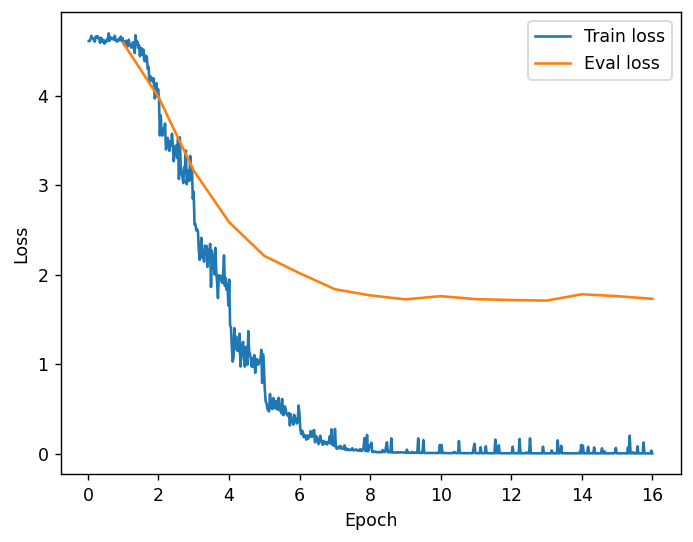

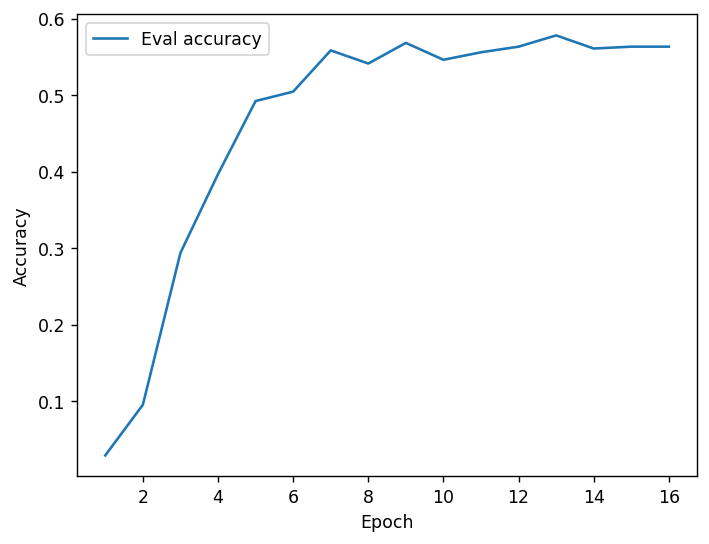

In [18]:
import glob

ckpt = max(glob.glob("asl_model/checkpoint-*"), key=lambda p: int(p.split("-")[-1]))
logs = json.load(open(f"{ckpt}/trainer_state.json"))["log_history"]
json.dump(logs, open("vm_log_history.json", "w"))

train_loss = [(l["epoch"], l["loss"]) for l in logs if "loss" in l]
eval_loss  = [(l["epoch"], l["eval_loss"]) for l in logs if "eval_loss" in l]
eval_acc   = [(l["epoch"], l["eval_accuracy"]) for l in logs if "eval_accuracy" in l]

plt.figure()
plt.plot(*zip(*train_loss), label="Train loss")
plt.plot(*zip(*eval_loss), label="Eval loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
plt.savefig("loss_curve.png"); plt.show()

plt.figure()
plt.plot(*zip(*eval_acc), label="Eval accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()
plt.savefig("accuracy_curve.png"); plt.show()

In [20]:
import urllib.request

if not os.path.exists("hand_landmarker.task"):
    url = "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task"
    urllib.request.urlretrieve(url, "hand_landmarker.task")

base_options = BaseOptions(model_asset_path="hand_landmarker.task")
options = HandLandmarkerOptions(
    base_options=base_options,
    num_hands=2,
    running_mode=RunningMode.IMAGE
)
detector = HandLandmarker.create_from_options(options)

In [21]:
def extract_landmarks(image_path):
    img = cv2.imread(image_path)
    if img is None:
        return np.zeros((2, 21, 3))

    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
    result = detector.detect(mp_image)

    hands_data = np.zeros((2, 21, 3))
    if result.hand_landmarks:
        for i, hand in enumerate(result.hand_landmarks[:2]):
            for j, lm in enumerate(hand):
                hands_data[i, j] = [lm.x, lm.y, lm.z]

    return hands_data

def extract_sequence(folder_path, num_frames=16):
    frame_files = sorted(os.listdir(folder_path))
    idxs = np.linspace(0, len(frame_files) - 1, num_frames).astype(int)

    seq = []
    for i in idxs:
        path = os.path.join(folder_path, frame_files[i])
        landmarks = extract_landmarks(path)
        seq.append(landmarks.flatten())  # 126 features per frame

    return np.array(seq)  # shape: (16, 126)


In [22]:
pose_rows = []
for idx, row in tqdm(df.iterrows(), total=len(df)):
    seq = extract_sequence(row["path"])
    pose_rows.append({
        "split": row["split"],
        "label_int": row["label_int"],
        "word": row["word"],
        "sequence": seq
    })

pose_df = pd.DataFrame(pose_rows)
np.save("pose_sequences.npy", pose_df.to_dict(), allow_pickle=True)
print(pose_df.shape)

100%|██████████| 2035/2035 [11:23<00:00,  2.98it/s]

(2035, 4)


In [23]:
from torch.utils.data import DataLoader, Dataset


class PoseDataset(Dataset):
    def __init__(self, pose_df):
        self.df = pose_df.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        seq = torch.tensor(row["sequence"], dtype=torch.float32)
        label = row["label_int"]
        return seq, label

train_pose = pose_df[pose_df["split"] == "train"]
test_pose = pose_df[pose_df["split"] == "test"]

train_pose_ds = PoseDataset(train_pose)
test_pose_ds = PoseDataset(test_pose)

In [24]:
from torch import nn


class SignLSTM(nn.Module):
    def __init__(self, input_size=126, hidden_size=256, num_classes=100, bidirectional=False, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True, bidirectional=bidirectional)
        direction = 2 if bidirectional else 1
        self.bn = nn.BatchNorm1d(hidden_size * direction)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size * direction, num_classes)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]
        out = self.bn(out)
        out = self.dropout(out)
        return self.fc(out)

In [25]:
train_loader = DataLoader(train_pose_ds, batch_size=8, shuffle=True, drop_last=True)
test_loader = DataLoader(test_pose_ds, batch_size=8)


def train_model(bidirectional=False, epochs=60, lr=1e-3, hidden_size=128):
    model = SignLSTM(hidden_size=hidden_size, bidirectional=bidirectional).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)
    criterion = nn.CrossEntropyLoss()

    history = {"train_loss": [], "test_loss": [], "test_acc": []}

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for seq, labels in train_loader:
            seq, labels = seq.to(device), labels.to(device)
            optimizer.zero_grad()
            out = model(seq)
            loss = criterion(out, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        train_loss = total_loss / len(train_loader)

        model.eval()
        test_loss, correct, total = 0, 0, 0
        with torch.no_grad():
            for seq, labels in test_loader:
                seq, labels = seq.to(device), labels.to(device)
                out = model(seq)
                loss = criterion(out, labels)
                test_loss += loss.item()
                preds = out.argmax(-1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)

        test_loss /= len(test_loader)
        test_acc = correct / total
        scheduler.step(test_loss)

        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)

        print(f"Epoch {epoch+1}: train_loss={train_loss:.3f} test_loss={test_loss:.3f} test_acc={test_acc:.3f}")

    return model, history



In [26]:
def normalize_sequence(seq):
    # seq shape: (16, 126) -> reshape to (16, 2, 21, 3)
    seq = seq.reshape(16, 2, 21, 3).copy()

    for t in range(seq.shape[0]):
        for h in range(2):
            hand = seq[t, h]
            if np.all(hand == 0):
                continue

            wrist = hand[0].copy()
            hand -= wrist  # center on wrist

            scale = np.linalg.norm(hand, axis=1).max()
            if scale > 0:
                hand /= scale

            seq[t, h] = hand

    return seq.reshape(16, 126)

pose_df["sequence"] = pose_df["sequence"].apply(normalize_sequence)

In [27]:
train_pose = pose_df[pose_df["split"] == "train"]
test_pose = pose_df[pose_df["split"] == "test"]

train_pose_ds = PoseDataset(train_pose)
test_pose_ds = PoseDataset(test_pose)

train_loader = DataLoader(train_pose_ds, batch_size=8, shuffle=True)
test_loader = DataLoader(test_pose_ds, batch_size=8)

lstm_model, lstm_history = train_model(bidirectional=False)

Epoch 1: train_loss=4.432 test_loss=4.039 test_acc=0.071
Epoch 2: train_loss=3.936 test_loss=3.789 test_acc=0.100
Epoch 3: train_loss=3.553 test_loss=3.303 test_acc=0.159
Epoch 4: train_loss=3.174 test_loss=3.082 test_acc=0.225
Epoch 5: train_loss=2.910 test_loss=2.976 test_acc=0.218
Epoch 6: train_loss=2.683 test_loss=2.886 test_acc=0.262
Epoch 7: train_loss=2.512 test_loss=2.810 test_acc=0.270
Epoch 8: train_loss=2.276 test_loss=2.886 test_acc=0.250
Epoch 9: train_loss=2.139 test_loss=2.602 test_acc=0.328
Epoch 10: train_loss=1.987 test_loss=2.623 test_acc=0.326
Epoch 11: train_loss=1.861 test_loss=2.554 test_acc=0.370
Epoch 12: train_loss=1.710 test_loss=2.390 test_acc=0.385
Epoch 13: train_loss=1.625 test_loss=2.418 test_acc=0.375
Epoch 14: train_loss=1.440 test_loss=2.281 test_acc=0.417
Epoch 15: train_loss=1.375 test_loss=2.391 test_acc=0.395
Epoch 16: train_loss=1.265 test_loss=2.446 test_acc=0.409
Epoch 17: train_loss=1.159 test_loss=2.323 test_acc=0.412
Epoch 18: train_loss=1.

In [28]:
bilstm_model, bilstm_history = train_model(bidirectional=True)

Epoch 1: train_loss=4.451 test_loss=4.071 test_acc=0.066
Epoch 2: train_loss=3.874 test_loss=3.676 test_acc=0.150
Epoch 3: train_loss=3.528 test_loss=3.461 test_acc=0.181
Epoch 4: train_loss=3.131 test_loss=3.229 test_acc=0.199
Epoch 5: train_loss=2.846 test_loss=3.005 test_acc=0.233
Epoch 6: train_loss=2.560 test_loss=2.868 test_acc=0.270
Epoch 7: train_loss=2.331 test_loss=2.807 test_acc=0.304
Epoch 8: train_loss=2.190 test_loss=2.657 test_acc=0.314
Epoch 9: train_loss=2.040 test_loss=2.726 test_acc=0.333
Epoch 10: train_loss=1.855 test_loss=2.564 test_acc=0.343
Epoch 11: train_loss=1.759 test_loss=2.532 test_acc=0.358
Epoch 12: train_loss=1.663 test_loss=2.563 test_acc=0.358
Epoch 13: train_loss=1.528 test_loss=2.516 test_acc=0.390
Epoch 14: train_loss=1.396 test_loss=2.434 test_acc=0.377
Epoch 15: train_loss=1.226 test_loss=2.428 test_acc=0.392
Epoch 16: train_loss=1.198 test_loss=2.460 test_acc=0.434
Epoch 17: train_loss=1.165 test_loss=2.605 test_acc=0.414
Epoch 18: train_loss=1.

In [29]:
lstm_model, lstm_history = train_model(bidirectional=False, hidden_size=256)


Epoch 1: train_loss=4.410 test_loss=4.068 test_acc=0.064
Epoch 2: train_loss=3.816 test_loss=3.530 test_acc=0.132
Epoch 3: train_loss=3.396 test_loss=3.265 test_acc=0.191
Epoch 4: train_loss=3.140 test_loss=3.103 test_acc=0.218
Epoch 5: train_loss=2.795 test_loss=2.904 test_acc=0.267
Epoch 6: train_loss=2.532 test_loss=2.768 test_acc=0.272
Epoch 7: train_loss=2.305 test_loss=2.746 test_acc=0.314
Epoch 8: train_loss=2.126 test_loss=2.563 test_acc=0.314
Epoch 9: train_loss=1.870 test_loss=2.469 test_acc=0.365
Epoch 10: train_loss=1.670 test_loss=2.704 test_acc=0.341
Epoch 11: train_loss=1.587 test_loss=2.488 test_acc=0.382
Epoch 12: train_loss=1.398 test_loss=2.638 test_acc=0.355
Epoch 13: train_loss=1.295 test_loss=2.635 test_acc=0.368
Epoch 14: train_loss=1.076 test_loss=2.651 test_acc=0.387
Epoch 15: train_loss=0.972 test_loss=2.633 test_acc=0.397
Epoch 16: train_loss=0.673 test_loss=2.328 test_acc=0.468
Epoch 17: train_loss=0.527 test_loss=2.360 test_acc=0.441
Epoch 18: train_loss=0.

In [30]:
lstm_model, lstm_history = train_model(bidirectional=True, hidden_size=256)


Epoch 1: train_loss=4.529 test_loss=4.293 test_acc=0.083
Epoch 2: train_loss=4.006 test_loss=3.998 test_acc=0.093
Epoch 3: train_loss=3.543 test_loss=3.594 test_acc=0.159
Epoch 4: train_loss=3.134 test_loss=3.381 test_acc=0.176
Epoch 5: train_loss=2.868 test_loss=3.216 test_acc=0.208
Epoch 6: train_loss=2.570 test_loss=3.205 test_acc=0.208
Epoch 7: train_loss=2.328 test_loss=2.713 test_acc=0.341
Epoch 8: train_loss=2.106 test_loss=2.895 test_acc=0.277
Epoch 9: train_loss=1.933 test_loss=2.934 test_acc=0.326
Epoch 10: train_loss=1.748 test_loss=2.646 test_acc=0.377
Epoch 11: train_loss=1.530 test_loss=2.644 test_acc=0.385
Epoch 12: train_loss=1.460 test_loss=2.829 test_acc=0.363
Epoch 13: train_loss=1.237 test_loss=2.649 test_acc=0.407
Epoch 14: train_loss=1.162 test_loss=2.592 test_acc=0.390
Epoch 15: train_loss=1.069 test_loss=2.782 test_acc=0.419
Epoch 16: train_loss=0.916 test_loss=2.778 test_acc=0.422
Epoch 17: train_loss=0.870 test_loss=2.938 test_acc=0.402
Epoch 18: train_loss=0.

In [19]:
class SignLSTMlayer(nn.Module):
    def __init__(self, input_size=126, hidden_size=256, num_classes=100, bidirectional=False, dropout=0.3, num_layers = 2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size, hidden_size, 
            batch_first=True, 
            bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0.0
        )
        direction = 2 if bidirectional else 1
        self.bn = nn.BatchNorm1d(hidden_size * direction)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size * direction, num_classes)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]
        out = self.bn(out)
        out = self.dropout(out)
        return self.fc(out)

def train_model_layer(bidirectional=False, epochs=50, lr=1e-3, hidden_size=128):
    model = SignLSTMlayer(hidden_size=hidden_size, bidirectional=bidirectional).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)
    criterion = nn.CrossEntropyLoss()

    history = {"train_loss": [], "test_loss": [], "test_acc": []}

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for seq, labels in train_loader:
            seq, labels = seq.to(device), labels.to(device)
            optimizer.zero_grad()
            out = model(seq)
            loss = criterion(out, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        train_loss = total_loss / len(train_loader)

        model.eval()
        test_loss, correct, total = 0, 0, 0
        with torch.no_grad():
            for seq, labels in test_loader:
                seq, labels = seq.to(device), labels.to(device)
                out = model(seq)
                loss = criterion(out, labels)
                test_loss += loss.item()
                preds = out.argmax(-1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)

        test_loss /= len(test_loader)
        test_acc = correct / total
        scheduler.step(test_loss)

        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)

        print(f"Epoch {epoch+1}: train_loss={train_loss:.3f} test_loss={test_loss:.3f} test_acc={test_acc:.3f}")

    return model, history

In [ ]:
lstm_model, lstm_history = train_model_layer(bidirectional=True,epochs= 60, hidden_size=256)

Epoch 1: train_loss=4.513 test_loss=4.070 test_acc=0.069
Epoch 2: train_loss=3.970 test_loss=4.044 test_acc=0.108
Epoch 3: train_loss=3.666 test_loss=3.793 test_acc=0.147
Epoch 4: train_loss=3.238 test_loss=3.429 test_acc=0.172
Epoch 5: train_loss=2.966 test_loss=3.262 test_acc=0.216
Epoch 6: train_loss=2.690 test_loss=3.084 test_acc=0.248
Epoch 7: train_loss=2.432 test_loss=2.899 test_acc=0.265
Epoch 8: train_loss=2.131 test_loss=2.819 test_acc=0.297
Epoch 9: train_loss=1.961 test_loss=2.862 test_acc=0.297
Epoch 10: train_loss=1.814 test_loss=2.861 test_acc=0.319
Epoch 11: train_loss=1.655 test_loss=2.813 test_acc=0.348
Epoch 12: train_loss=1.485 test_loss=2.756 test_acc=0.353
Epoch 13: train_loss=1.275 test_loss=2.736 test_acc=0.377
Epoch 14: train_loss=1.179 test_loss=2.756 test_acc=0.363
Epoch 15: train_loss=1.079 test_loss=2.839 test_acc=0.407
Epoch 16: train_loss=1.011 test_loss=2.850 test_acc=0.402
Epoch 17: train_loss=0.961 test_loss=2.965 test_acc=0.385
Epoch 18: train_loss=0.

In [ ]:
import numpy as np
import torch
import torch.nn.functional as F

model.eval()
lstm_model.eval()
device = "cuda" if torch.cuda.is_available() else "cpu"

all_labels = []
fused_preds = []

for i in range(len(test_df)):
    # VideoMAE prediction
    vmae_row = test_ds[i]
    pixel_values = vmae_row["pixel_values"].unsqueeze(0).to(device)
    with torch.no_grad():
        vmae_logits = model(pixel_values=pixel_values).logits
        vmae_probs = F.softmax(vmae_logits, dim=-1).cpu().numpy()[0]

    # LSTM prediction (matching video, same index in test_pose)
    seq, label = test_pose_ds[i]
    seq = seq.unsqueeze(0).to(device)
    with torch.no_grad():
        lstm_logits = lstm_model(seq)
        lstm_probs = F.softmax(lstm_logits, dim=-1).cpu().numpy()[0]

    # Fuse: weighted average
    fused = 0.65 * vmae_probs + 0.35 * lstm_probs
    pred = np.argmax(fused)

    fused_preds.append(pred)
    all_labels.append(label)

accuracy = np.mean(np.array(fused_preds) == np.array(all_labels))
print("Fused accuracy:", accuracy)

Fused accuracy: 0.6151960784313726


105it [00:33,  3.13it/s]                         


          Top-1  Top-5  Precision  Recall     F1
VideoMAE  0.542  0.816      0.570   0.541  0.528
LSTM      0.502  0.765      0.492   0.499  0.473
BiLSTM    0.490  0.765      0.483   0.486  0.465


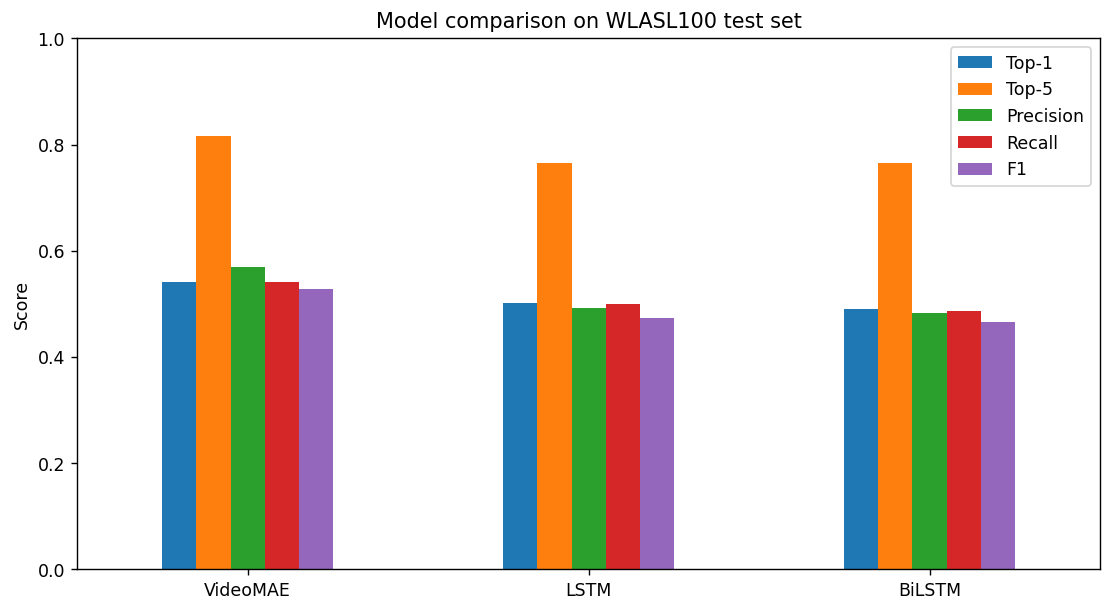

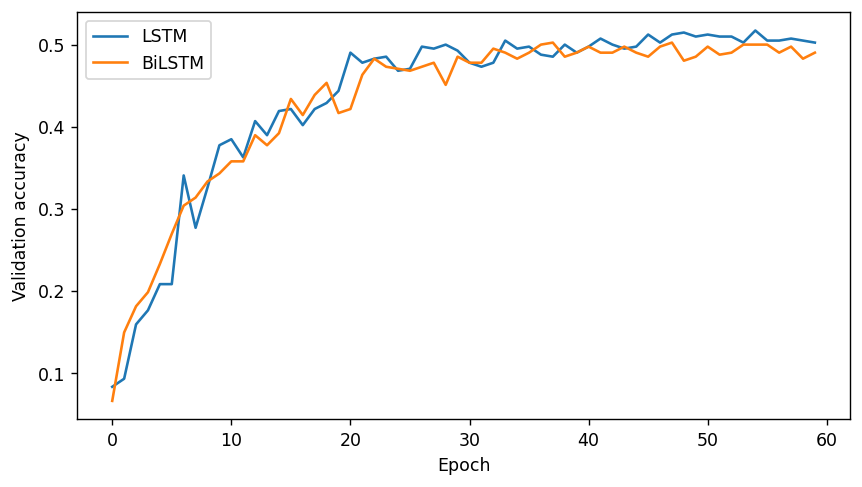

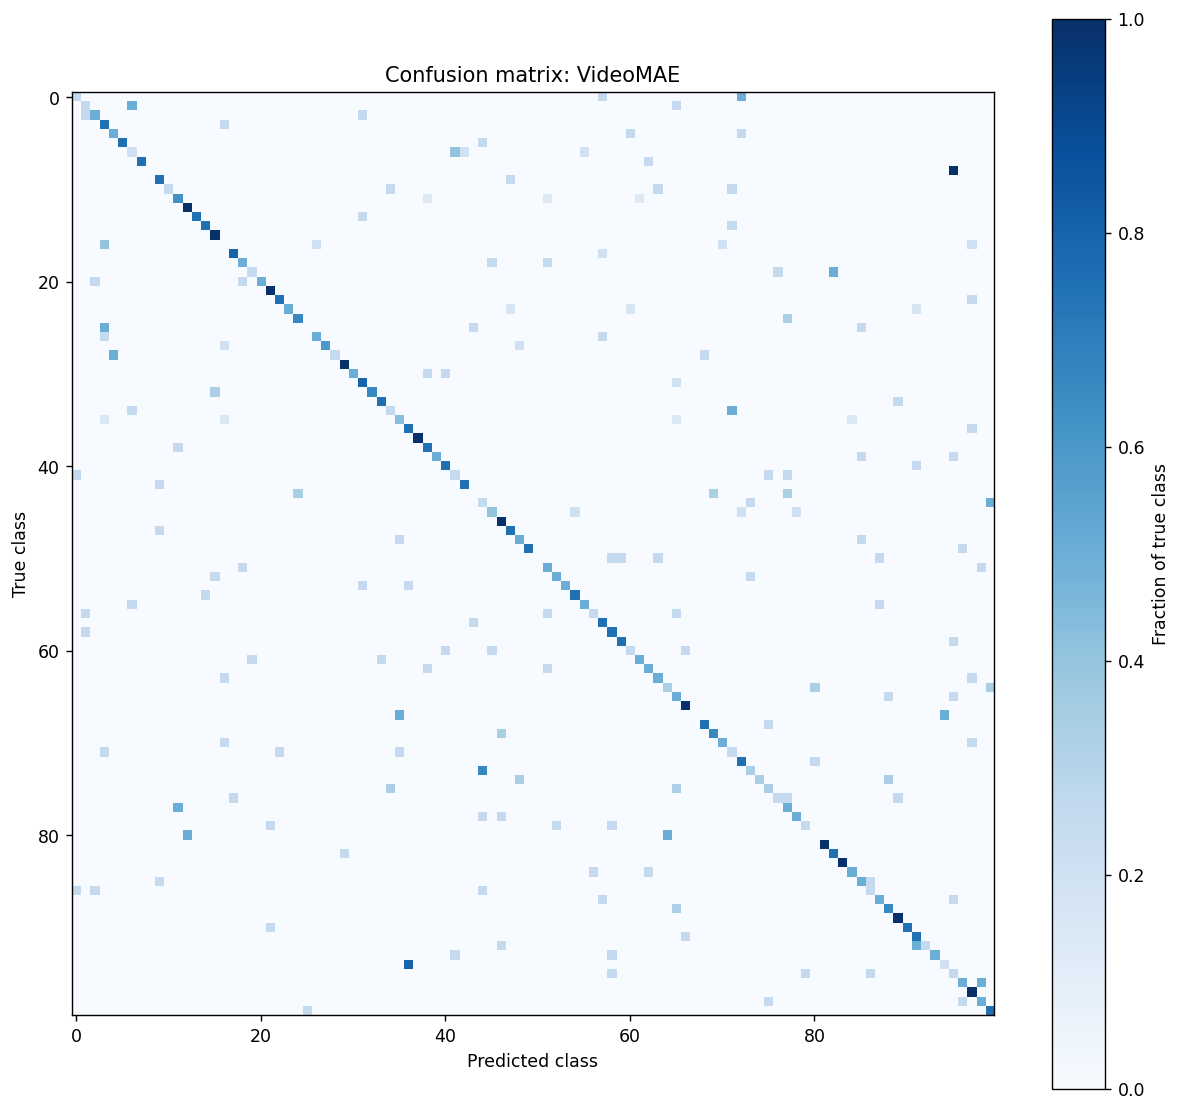

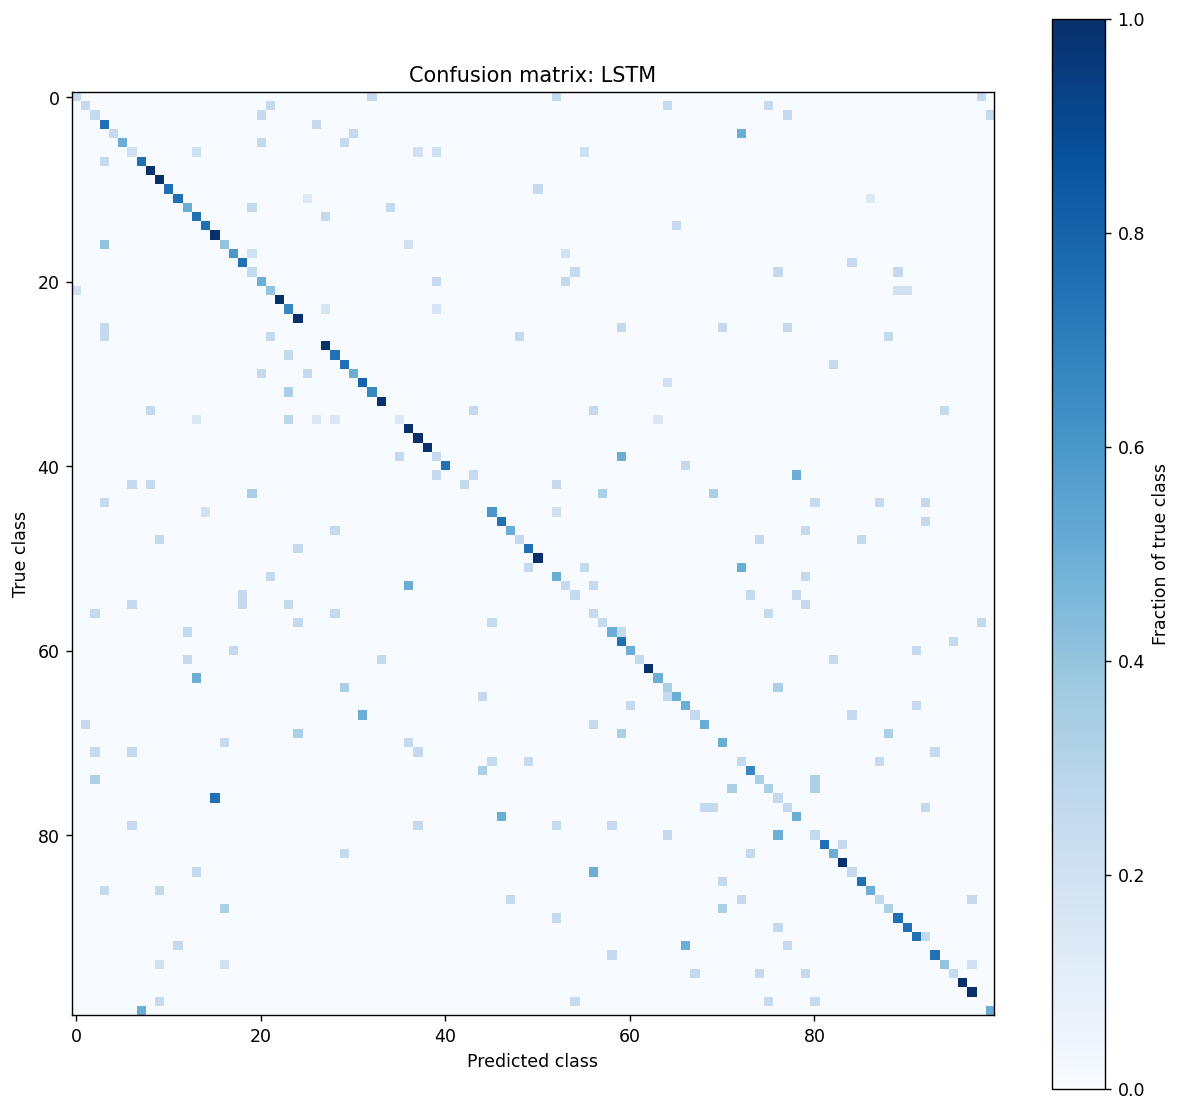

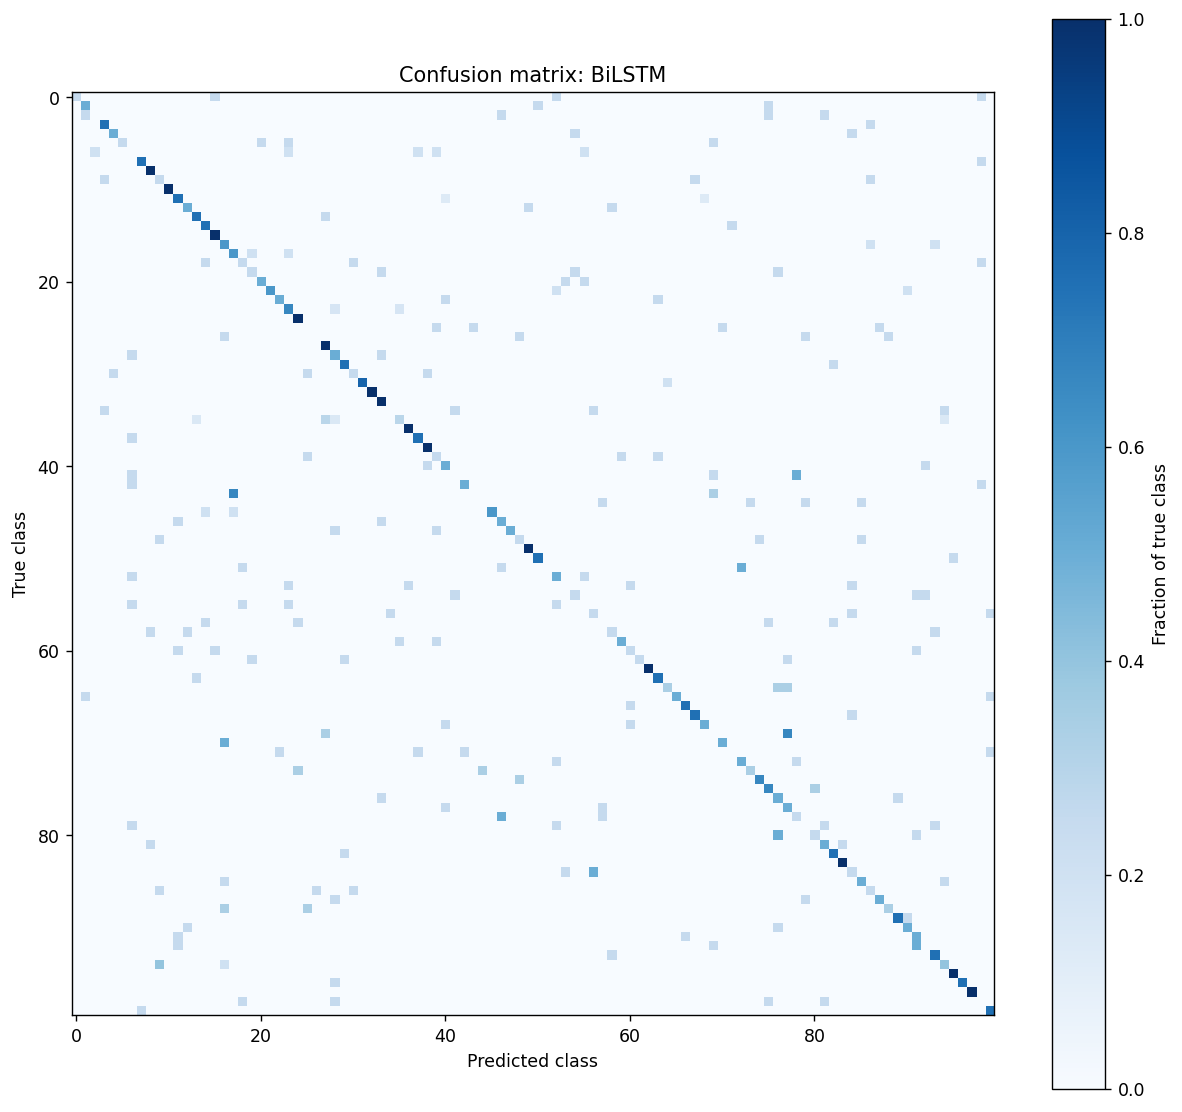

        word  precision  recall        f1  support
80     short   0.000000    0.00  0.000000        4
50       hot   0.000000    0.00  0.000000        4
43      full   0.000000    0.00  0.000000        3
25      cool   0.000000    0.00  0.000000        4
16     candy   0.000000    0.00  0.000000        5
8   birthday   0.000000    0.00  0.000000        4
67    orange   0.000000    0.00  0.000000        4
94       who   0.333333    0.20  0.250000        5
6     before   0.200000    0.20  0.200000        5
60      many   0.333333    0.25  0.285714        4
71     pizza   0.200000    0.25  0.222222        4
56     later   0.500000    0.25  0.333333        4
1     africa   0.250000    0.25  0.250000        4
44      give   0.166667    0.25  0.200000        4
41      fish   0.250000    0.25  0.250000        4
        word  precision  recall        f1  support
47       hat   0.600000    0.75  0.666667        4
42    forget   0.750000    0.75  0.750000        4
31      deaf   0.571429    0.80

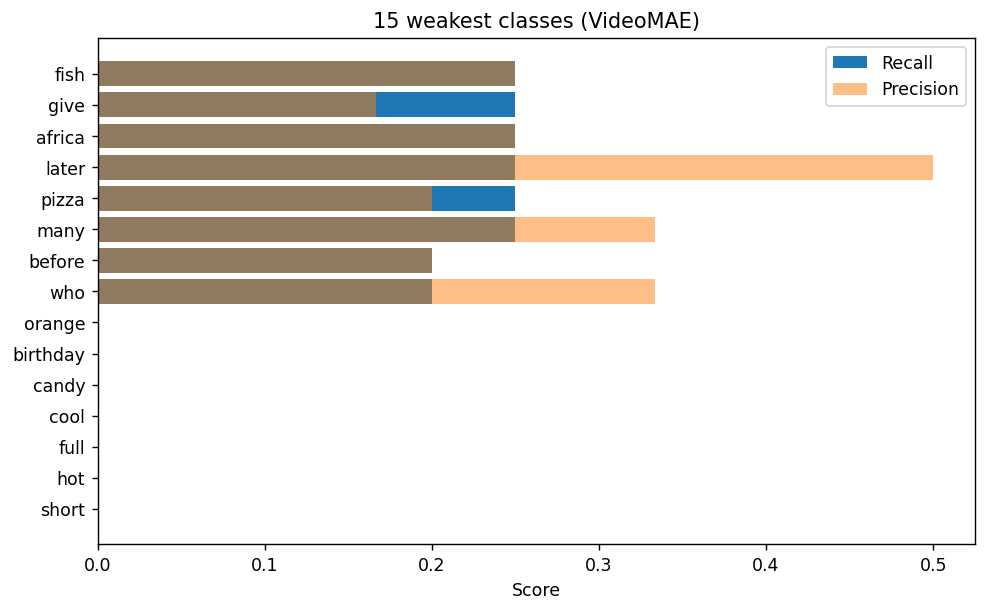

birthday -> woman: 4
who -> eat: 4
cow -> basketball: 2
orange -> who: 2
short -> bowling: 2
accident -> play: 2
school -> book: 2
give -> yes: 2
dog -> pizza: 2
work -> year: 2


In [39]:
from sklearn.metrics import (
    confusion_matrix,
    precision_recall_fscore_support,
)

names = [label_map[str(i)] for i in range(100)]

# ---- 1. Get logits + labels per model ----
pred_out = trainer.predict(test_ds)
vm_logits, vm_labels = pred_out.predictions, pred_out.label_ids

def lstm_predict(model, loader):
    model.eval()
    logits, labels = [], []
    with torch.no_grad():
        for seq, y in loader:
            logits.append(model(seq.to(device)).cpu().numpy())
            labels.append(y.numpy())
    return np.concatenate(logits), np.concatenate(labels)

ls_logits, ls_labels = lstm_predict(lstm_model, test_loader)
bi_logits, bi_labels = lstm_predict(bilstm_model, test_loader)

results = {
    "VideoMAE": (vm_logits, vm_labels),
    "LSTM": (ls_logits, ls_labels),
    "BiLSTM": (bi_logits, bi_labels),
}

# ---- 2. Metrics ----
def evaluate(logits, labels):
    preds = logits.argmax(1)
    top5 = np.argsort(logits, axis=1)[:, -5:]
    top5_acc = np.mean([l in t for l, t in zip(labels, top5)])
    p, r, f, _ = precision_recall_fscore_support(
        labels, preds, average="macro", zero_division=0)
    return {"Top-1": (preds == labels).mean(), "Top-5": top5_acc,
            "Precision": p, "Recall": r, "F1": f}

metrics = {n: evaluate(*v) for n, v in results.items()}
metrics_df = pd.DataFrame(metrics).T.round(3)
print(metrics_df)
metrics_df.to_csv("metrics_summary.csv")

# ---- 3. Figure: accuracy/metric comparison ----
metrics_df.plot(kind="bar", figsize=(9, 5))
plt.ylabel("Score")
plt.title("Model comparison on WLASL100 test set")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig("fig_model_comparison.png", dpi=200)
plt.show()

# ---- 4. Figure: LSTM / BiLSTM validation accuracy curves ----
plt.figure(figsize=(7, 4))
plt.plot(lstm_history["test_acc"], label="LSTM")
plt.plot(bilstm_history["test_acc"], label="BiLSTM")
plt.xlabel("Epoch"); plt.ylabel("Validation accuracy"); plt.legend()
plt.tight_layout()
plt.savefig("fig_lstm_test_acc.png", dpi=200)
plt.show()

# ---- 5. Confusion matrix (row-normalised = per-class recall) ----
def plot_confusion(name, logits, labels):
    preds = logits.argmax(1)
    cm = confusion_matrix(labels, preds, labels=range(100), normalize="true")
    plt.figure(figsize=(10, 9))
    plt.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    plt.colorbar(label="Fraction of true class")
    plt.xlabel("Predicted class"); plt.ylabel("True class")
    plt.title(f"Confusion matrix: {name}")
    plt.tight_layout()
    plt.savefig(f"fig_confusion_{name}.png", dpi=200)
    plt.show()

for n, (lg, lb) in results.items():
    plot_confusion(n, lg, lb)

# ---- 6. Per-class precision / recall ----
def per_class_table(logits, labels):
    preds = logits.argmax(1)
    p, r, f, s = precision_recall_fscore_support(
        labels, preds, labels=range(100), zero_division=0)
    return pd.DataFrame({"word": names, "precision": p, "recall": r,
                         "f1": f, "support": s})

best = "VideoMAE"
pc = per_class_table(*results[best]).sort_values("recall")
print(pc.head(15))   # worst classes
print(pc.tail(15))   # best classes
pc.to_csv(f"per_class_{best}.csv", index=False)

# Worst-15 bar chart
worst = pc.head(15)
plt.figure(figsize=(8, 5))
plt.barh(worst["word"], worst["recall"], label="Recall")
plt.barh(worst["word"], worst["precision"], alpha=0.5, label="Precision")
plt.xlabel("Score"); plt.title(f"15 weakest classes ({best})"); plt.legend()
plt.tight_layout()
plt.savefig("fig_worst_classes.png", dpi=200)
plt.show()

# ---- 7. Most confused sign pairs ----
preds = results[best][0].argmax(1)
cm = confusion_matrix(results[best][1], preds, labels=range(100))
np.fill_diagonal(cm, 0)
pairs = [(names[i], names[j], cm[i, j])
         for i, j in zip(*np.unravel_index(np.argsort(cm, axis=None)[::-1][:10], cm.shape))]
for true, pred, n in pairs:
    print(f"{true} -> {pred}: {n}")

In [40]:
import numpy as np
from sklearn.metrics import classification_report

# y_true, y_pred from your pred_out
y_true = pred_out.label_ids
y_pred = pred_out.predictions.argmax(-1)

# 1. Are the classes present in the test set at all?
print("test class counts:", np.bincount(y_true, minlength=100))

# 2. Full report (macro/weighted) — sanity check
print(classification_report(y_true, y_pred, digits=3, zero_division=0))

# 3. Which classes are never predicted?
never_pred = np.setdiff1d(np.arange(100), np.unique(y_pred))
never_true = np.setdiff1d(np.arange(100), np.unique(y_true))
print("never predicted:", never_pred)
print("never in test :", never_true)

test class counts: [4 4 4 4 4 4 5 4 4 4 4 8 4 4 4 4 5 5 4 4 4 5 4 6 3 4 4 5 4 4 4 5 3 4 4 7 4 4 4
 4 4 4 4 3 4 5 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 3 4 4 4 4 3 4 4 4 3 3 3 4 4
 4 4 4 4 4 4 4 4 4 4 3 4 4 4 4 4 5 4 4 4 4 4]
              precision    recall  f1-score   support

           0      0.333     0.250     0.286         4
           1      0.250     0.250     0.250         4
           2      0.500     0.500     0.500         4
           3      0.300     0.750     0.429         4
           4      0.500     0.500     0.500         4
           5      1.000     0.750     0.857         4
           6      0.200     0.200     0.200         5
           7      1.000     0.750     0.857         4
           8      0.000     0.000     0.000         4
           9      0.500     0.750     0.600         4
          10      1.000     0.250     0.400         4
          11      0.625     0.625     0.625         8
          12      0.667     1.000     0.800         4
          13      1.

In [35]:
import gc
import random

from scipy import stats

SEEDS = list(range(30))  

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


In [ ]:
# ---------- LSTM / BiLSTM, seeded ----------
def run_lstm(seed, bidirectional, epochs=60, lr=1e-3, hidden_size=256):
    set_seed(seed)
    g = torch.Generator().manual_seed(seed)
    loader = DataLoader(train_pose_ds, batch_size=8, shuffle=True,
                        drop_last=True, generator=g)
    in_dim = train_pose_ds[0][0].shape[-1]   # must be 126 (hands only)
    model = SignLSTM(input_size=in_dim, hidden_size=hidden_size,
                     bidirectional=bidirectional).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=5)
    crit = nn.CrossEntropyLoss()

    for _ in range(epochs):
        model.train()
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            crit(model(x), y).backward()
            opt.step()
        model.eval()
        vl, correct, n = 0, 0, 0
        with torch.no_grad():
            for x, y in test_loader:
                x, y = x.to(device), y.to(device)
                out = model(x)
                vl += crit(out, y).item()
                correct += (out.argmax(-1) == y).sum().item()
                n += y.size(0)
        sched.step(vl / len(test_loader))
    return correct / n          # final-epoch accuracy(not best epoch)

rows = []
for seed in SEEDS:
    for name, bi in [("LSTM", False), ("BiLSTM", True)]:
        rows.append({"model": name, "seed": seed,
                     "test_acc": run_lstm(seed, bi)})
    pd.DataFrame(rows).to_csv("runs_lstm.csv", index=False) 
    print("done seed", seed)


done seed 0
done seed 1
done seed 2
done seed 3
done seed 4
done seed 5
done seed 6
done seed 7
done seed 8
done seed 9
done seed 10
done seed 11
done seed 12
done seed 13
done seed 14
done seed 15
done seed 16
done seed 17
done seed 18
done seed 19
done seed 20
done seed 21
done seed 22
done seed 23
done seed 24
done seed 25
done seed 26
done seed 27
done seed 28
done seed 29


[transformers] You passed `num_labels=100` which is incompatible to the `id2label` map of length `400`.
Loading weights: 100%|██████████| 162/162 [00:00<00:00, 4549.59it/s]
[transformers] VideoMAEForVideoClassification LOAD REPORT from: MCG-NJU/videomae-base-finetuned-kinetics
Key                                                            | Status     |                                                                                           
---------------------------------------------------------------+------------+-------------------------------------------------------------------------------------------
videomae.encoder.layer.{0...11}.attention.attention.q_bias     | UNEXPECTED |                                                                                           
videomae.encoder.layer.{0...11}.attention.attention.v_bias     | UNEXPECTED |                                                                                           
videomae.encoder.layer.{0...11}.attention.atte

{'loss': '4.664', 'grad_norm': '4.584', 'learning_rate': '2.97e-05', 'epoch': '0.1229'}


  2%|▏         | 100/4884 [18:37<14:57:30, 11.26s/it]

{'loss': '4.635', 'grad_norm': '3.054', 'learning_rate': '2.939e-05', 'epoch': '0.2457'}


...

{'loss': '4.613', 'grad_norm': '3.359', 'learning_rate': '2.878e-05', 'epoch': '0.4914'}


  5%|▌         | 250/4884 [46:38<14:40:46, 11.40s/it]

{'loss': '4.63', 'grad_norm': '3.017', 'learning_rate': '2.847e-05', 'epoch': '0.6143'}


  5%|▌         | 258/4884 [48:10<14:50:10, 11.55s/it]

KeyboardInterrupt: 

In [21]:
import os

from transformers import set_seed as hf_set_seed

# ---------- VideoMAE, seeded ----------

VM_SEEDS = SEEDS[:3]
EPOCHS = 12
VM_CSV = "runs_videomae.csv"

vm_rows = pd.read_csv(VM_CSV).to_dict("records") if os.path.exists(VM_CSV) else []
done = {r["seed"] for r in vm_rows}

for seed in VM_SEEDS:
    if seed in done:
        print("skip seed", seed)
        continue
    hf_set_seed(seed)
    m = VideoMAEForVideoClassification.from_pretrained(
        model_name, num_labels=100, ignore_mismatched_sizes=True)
    a = TrainingArguments(
        output_dir=f"asl_model_seed{seed}",
        per_device_train_batch_size=4, per_device_eval_batch_size=4,
        num_train_epochs=EPOCHS, eval_strategy="no", save_strategy="no",
        learning_rate=3e-5, weight_decay=0.01, logging_steps=50,
        fp16=True, dataloader_num_workers=0,
        seed=seed, data_seed=seed, report_to="none")
    t = Trainer(model=m, args=a, train_dataset=train_ds,
                eval_dataset=test_ds, compute_metrics=compute_metrics)
    t.train()
    vm_rows.append({"model": "VideoMAE", "seed": seed,
                    "test_acc": t.evaluate()["eval_accuracy"]})
    pd.DataFrame(vm_rows).to_csv(VM_CSV, index=False)
    del t, m; gc.collect(); torch.cuda.empty_cache()

[transformers] You passed `num_labels=100` which is incompatible to the `id2label` map of length `400`.
Loading weights: 100%|██████████| 162/162 [00:00<00:00, 6285.23it/s]
[transformers] VideoMAEForVideoClassification LOAD REPORT from: MCG-NJU/videomae-base-finetuned-kinetics
Key                                                            | Status     |                                                                                           
---------------------------------------------------------------+------------+-------------------------------------------------------------------------------------------
videomae.encoder.layer.{0...11}.attention.attention.v_bias     | UNEXPECTED |                                                                                           
videomae.encoder.layer.{0...11}.attention.attention.q_bias     | UNEXPECTED |                                                                                           
videomae.encoder.layer.{0...11}.attention.atte

{'loss': '4.65', 'grad_norm': '5.673', 'learning_rate': '2.97e-05', 'epoch': '0.1229'}


  2%|▏         | 100/4884 [01:12<57:30,  1.39it/s]

{'loss': '4.638', 'grad_norm': '4.985', 'learning_rate': '2.939e-05', 'epoch': '0.2457'}


  3%|▎         | 150/4884 [01:49<59:47,  1.32it/s]  

...

 99%|█████████▉| 4850/4884 [1:00:55<00:25,  1.33it/s]

{'loss': '0.05952', 'grad_norm': '0.3398', 'learning_rate': '2.211e-07', 'epoch': '11.92'}


100%|██████████| 4884/4884 [1:01:21<00:00,  1.33it/s]


{'train_runtime': '3681', 'train_samples_per_second': '5.304', 'train_steps_per_second': '1.327', 'train_loss': '1.83', 'epoch': '12'}


100%|██████████| 102/102 [00:32<00:00,  3.18it/s]


BiLSTM: n=30 mean=0.499 sd=0.015 95%CI=[0.494, 0.505] min=0.471 max=0.529
LSTM: n=30 mean=0.515 sd=0.018 95%CI=[0.508, 0.522] min=0.488 max=0.551
VideoMAE: n=3 mean=0.560 sd=0.046 95%CI=[0.447, 0.674] min=0.510 max=0.598
WilcoxonResult(statistic=np.float64(71.0), pvalue=np.float64(0.001532555988735046))


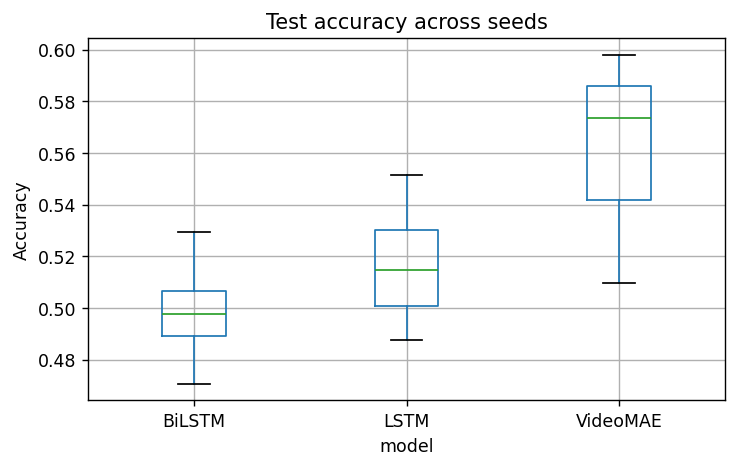

In [22]:
# ---------- Summary ----------
runs = pd.concat([pd.read_csv("runs_lstm.csv"),
                  pd.read_csv("runs_videomae.csv")])

def ci95(a):
    return stats.t.interval(0.95, len(a) - 1, loc=a.mean(), scale=stats.sem(a))

for name, g in runs.groupby("model"):
    a = g["test_acc"].values
    lo, hi = ci95(a)
    print(f"{name}: n={len(a)} mean={a.mean():.3f} sd={a.std(ddof=1):.3f} "
          f"95%CI=[{lo:.3f}, {hi:.3f}] min={a.min():.3f} max={a.max():.3f}")

# Paired test, same seeds
piv = runs[runs.model.isin(["LSTM", "BiLSTM"])].pivot(
    index="seed", columns="model", values="test_acc")
print(stats.wilcoxon(piv["LSTM"], piv["BiLSTM"]))

# Boxplot
runs.boxplot(column="test_acc", by="model", figsize=(6, 4))
plt.suptitle(""); plt.title("Test accuracy across seeds")
plt.ylabel("Accuracy"); plt.tight_layout()
plt.savefig("fig_seed_variance.png", dpi=200); plt.show()